# Marginal effects: what does "one more" do?

In the model basics lecture we found where the slope of `realinc ~ educ` came from. Today we ask what that slope *means*. Then we fit models where the answer depends on where you are.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ─────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## The data

Load the same GSS data set and drop the rows with missing values.

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |> drop_na(realinc, educ)

gss |> glimpse()

Rows: 67,731
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


## Recap: the slope is a marginal effect

Refit the line from last time.

In [3]:
fit_line <- linear_reg() |> fit(realinc ~ educ, data = gss)

fit_line

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


$$ \text{realinc} = a_1 + a_2 \times \text{educ} $$

The slope $a_2$ is about $3,600. It answers one question: *one more year of education gives how many more dollars?*

The answer to "what does one more unit of $x$ do to $y$?" has a name. It is the **marginal effect** of $x$.

Let's check this with predictions. Predict at 8 and 9 years, and at 15 and 16 years. Then take the difference between each pair.

In [4]:
grid_educ <- tibble(educ = c(8, 9, 15, 16))

fit_line |> predict(new_data = grid_educ) |> bind_cols(grid_educ)

  .pred    educ
1 14135.72  8  
2 17711.69  9  
3 39167.49 15  
4 42743.46 16  

In [5]:
fit_line |>
    predict(new_data = grid_educ) |>
    bind_cols(grid_educ) |>
    mutate(me = lead(.pred) - .pred)

  .pred    educ me       
1 14135.72  8    3575.967
2 17711.69  9   21455.801
3 39167.49 15    3575.967
4 42743.46 16          NA

`lead()` gets the next row. So `me` is the prediction at the next value minus the prediction at this one. (Ignore the row for 9 → 15. That is six years, not one.)

8 → 9 and 15 → 16 give the same number: the slope. For a straight line, the marginal effect is **the same everywhere**.

## The age–income hump

Now let's use `age` for $x$. Drop the rows with missing age. We also keep only ages under 90.

In [6]:
gss_age <- gss |> drop_na(age) |> filter(age < 90)

Like last time, we plot the **mean** income at each age.

**The model we create will still use every person, not just the mean value for each age**.

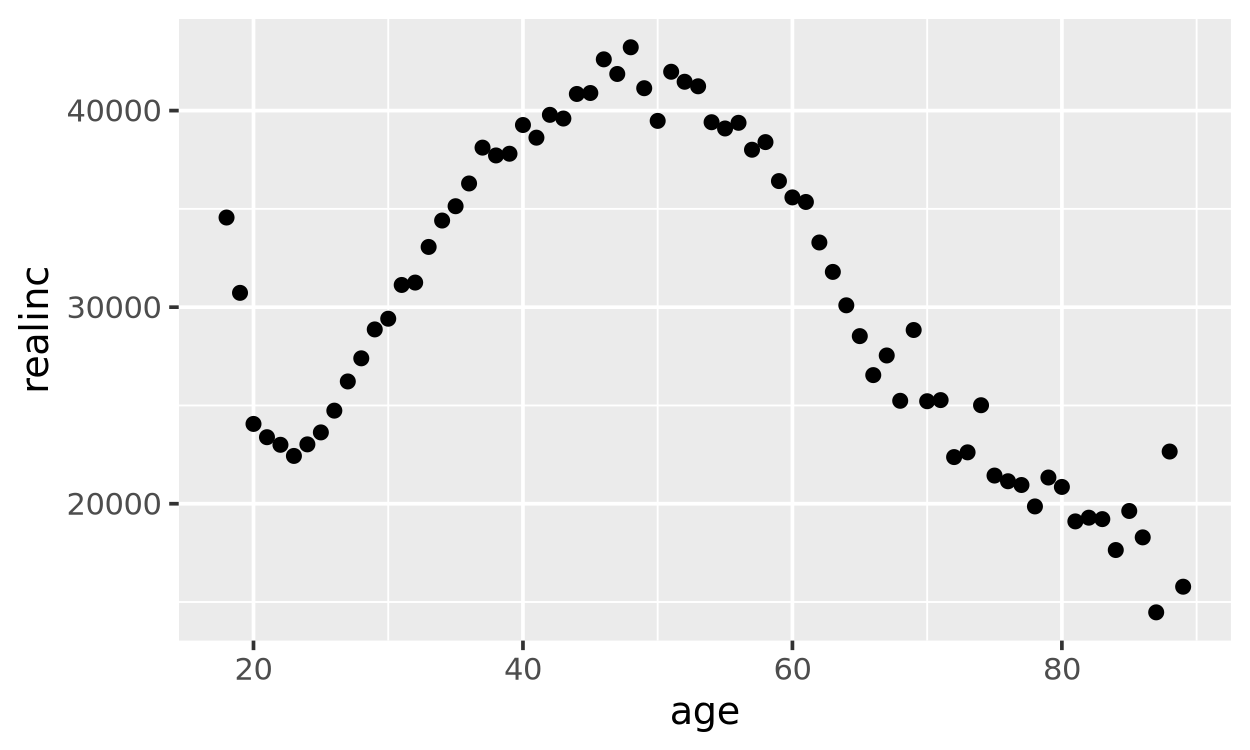

In [7]:
income_by_age <- gss_age |>
    group_by(age) |>
    summarize(realinc = mean(realinc))

ggplot(income_by_age, aes(x = age, y = realinc)) + geom_point()

This is not a line. Income goes up when people are young, flattens out, then goes down near retirement. A straight line is the wrong **model family** here.

### A curve

Add a squared term to get a curve:

$$ \text{realinc} = a_1 + a_2 \times \text{age} + a_3 \times \text{age}^2 $$

If $a_3$ is negative, the curve bends down like a hill. In a formula, `I(age^2)` means "compute `age^2`".

We still measure **distance** with squared residuals. `linear_reg()` still does the search for us.

In [8]:
fit_curve <- linear_reg() |> fit(realinc ~ age + I(age^2), data = gss_age)

fit_curve

parsnip model object


Call:
stats::lm(formula = realinc ~ age + I(age^2), data = data)

Coefficients:
(Intercept)          age     I(age^2)  
  -11107.60      2056.71       -21.12  


Now ask the same question: *one more year of age gives how many more dollars?*

There is no single number to point at. $a_2$ is not the answer, because $a_3$ also changes when age changes.

### Marginal effect by prediction differences

Use the same trick as the recap. Predict at every age from 18 to 85. Then take the difference between each age and the next age.

In [9]:
grid_age <- tibble(age = 18:85)

preds_age <- fit_curve |>
    predict(new_data = grid_age) |>
    bind_cols(grid_age) |>
    mutate(me = lead(.pred) - .pred)

preds_age |> head()

  .pred    age me      
1 19069.75 18  1275.203
2 20344.95 19  1232.959
3 21577.91 20  1190.715
4 22768.63 21  1148.471
5 23917.10 22  1106.227
6 25023.33 23  1063.983

In [10]:
preds_age |> filter(age %in% c(25, 40, 55, 65))

  .pred    age me       
1 27109.05 25   979.4955
2 37365.87 40   345.8374
3 38117.83 55  -287.8207
4 33338.65 65  -710.2594

At 25, one more year adds about $1,000. At 40, about $350. At 55, it **takes away** about $300. At 65, it takes away about $700.

Same model, four different answers. The marginal effect depends on **where you are**.

The marginal effect is zero at the top of the hill. Find the age where it changes from plus to minus.

In [11]:
preds_age |> filter(me > 0) |> slice_max(age, n = 1)

  .pred    age me      
1 38949.74 48  7.886401

From 48 to 49, income still goes up (by only $8). After that it goes down. Income peaks at about age 49.

### The marginal effect is the local slope

Draw the fitted curve over the mean-by-age points.

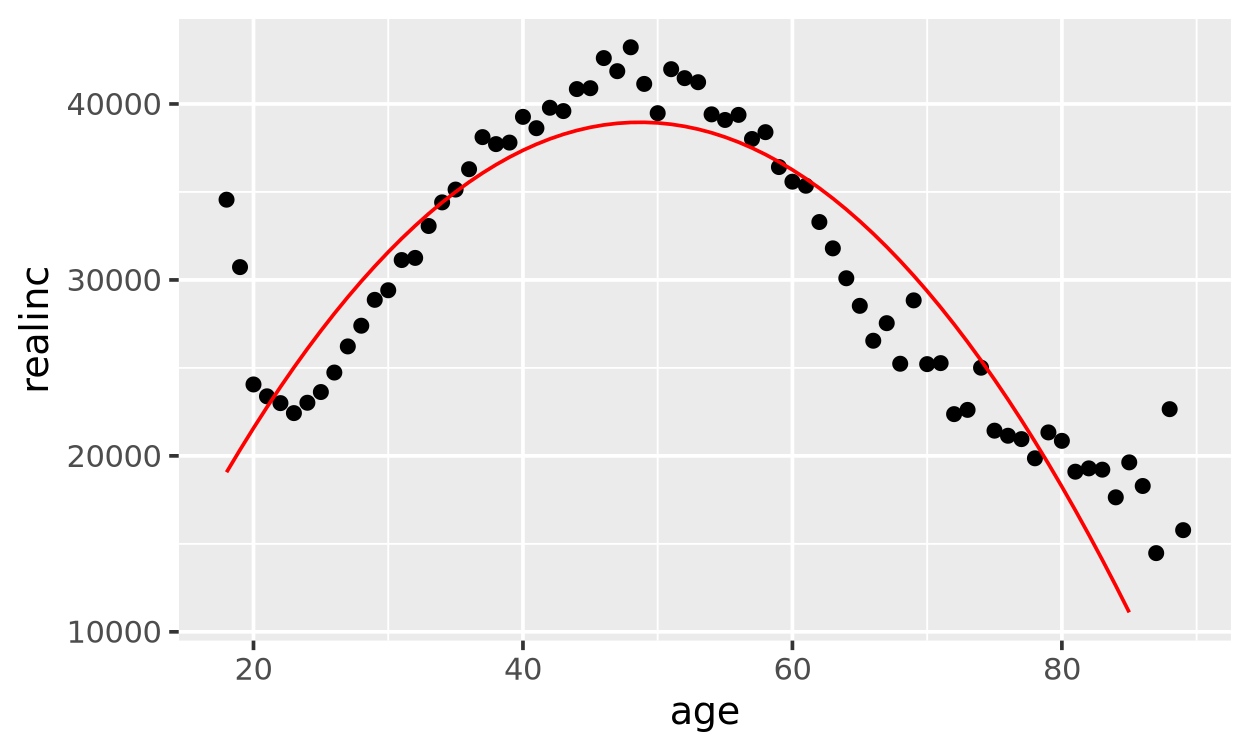

In [12]:
ggplot(income_by_age, aes(x = age, y = realinc)) +
    geom_point() +
    geom_line(data = preds_age, aes(y = .pred), color = 'red')

Now add a **tangent line** at age 25 and at age 60. A tangent line touches the curve at one point and has the same tilt there. Its slope is the marginal effect at that age.

`geom_abline()` needs an intercept. We pick the one that puts the line through the curve at that age: $\text{intercept} = \text{.pred} - \text{me} \times \text{age}$.

In [13]:
tangents <- preds_age |>
    filter(age %in% c(25, 60)) |>
    mutate(intercept = .pred - me * age)

tangents

  .pred    age me        intercept
1 27109.05 25   979.4955  2621.661
2 36256.29 60  -499.0401 66198.690

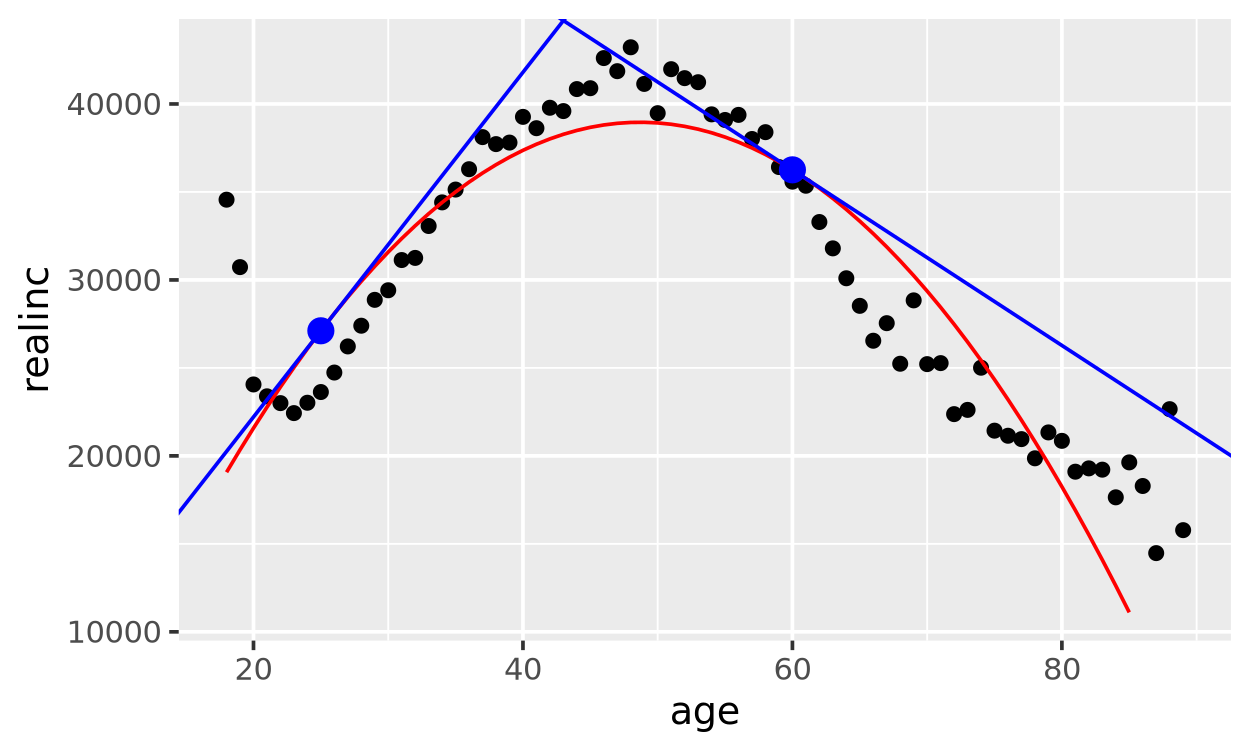

In [14]:
ggplot(income_by_age, aes(x = age, y = realinc)) +
    geom_point() +
    geom_line(data = preds_age, aes(y = .pred), color = 'red') +
    geom_abline(aes(intercept = intercept, slope = me), data = tangents, color = 'blue') +
    geom_point(data = tangents, aes(y = .pred), color = 'blue', size = 3)

At 25 the blue line tilts up. At 60 it tilts down. Each one is a small piece of a straight line from lecture 09. It is only true near that one age.

### Optional: the calculus shortcut

If you know calculus, the slope of the curve is its derivative:

$$ \frac{d\,\text{realinc}}{d\,\text{age}} = a_2 + 2 \times a_3 \times \text{age} $$

You do not need this. It is a shortcut that gives (almost) the same numbers as the prediction differences.

In [15]:
a <- tidy(fit_curve)$estimate

preds_age |>
    filter(age %in% c(25, 40, 55, 65)) |>
    mutate(calculus = a[2] + 2 * a[3] * age)

  .pred    age me        calculus 
1 27109.05 25   979.4955 1000.6174
2 37365.87 40   345.8374  366.9593
3 38117.83 55  -287.8207 -266.6988
4 33338.65 65  -710.2594 -689.1375

The two columns differ by about $20. The difference from 25 to 26 measures the slope halfway between, at 25.5. The derivative measures it at exactly 25.

## Log income

At the end of lecture 09 we saw that income is **skewed**: a few people earn a lot. A common fix is to model the **log** of income. Log makes large values closer together.

In [16]:
fit_log <- linear_reg() |> fit(log(realinc) ~ educ, data = gss)

fit_log

parsnip model object


Call:
stats::lm(formula = log(realinc) ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     8.3081       0.1251  


$$ \log(\text{realinc}) = a_1 + a_2 \times \text{educ} $$

The slope is about 0.125. This model is a straight line, but on the **log scale**.

On the log scale, adding 0.125 is roughly the same as *multiplying* by 1.125. So one more year of education gives about **12.5% more income**. (The exact number is $e^{0.125} \approx 1.13$, or 13%.)

Let's look at it. Plot the mean of `log(realinc)` at each education level. Then draw the fitted line with `geom_abline()`.

**The model is still fit on every person, not just the mean value for each education level**.

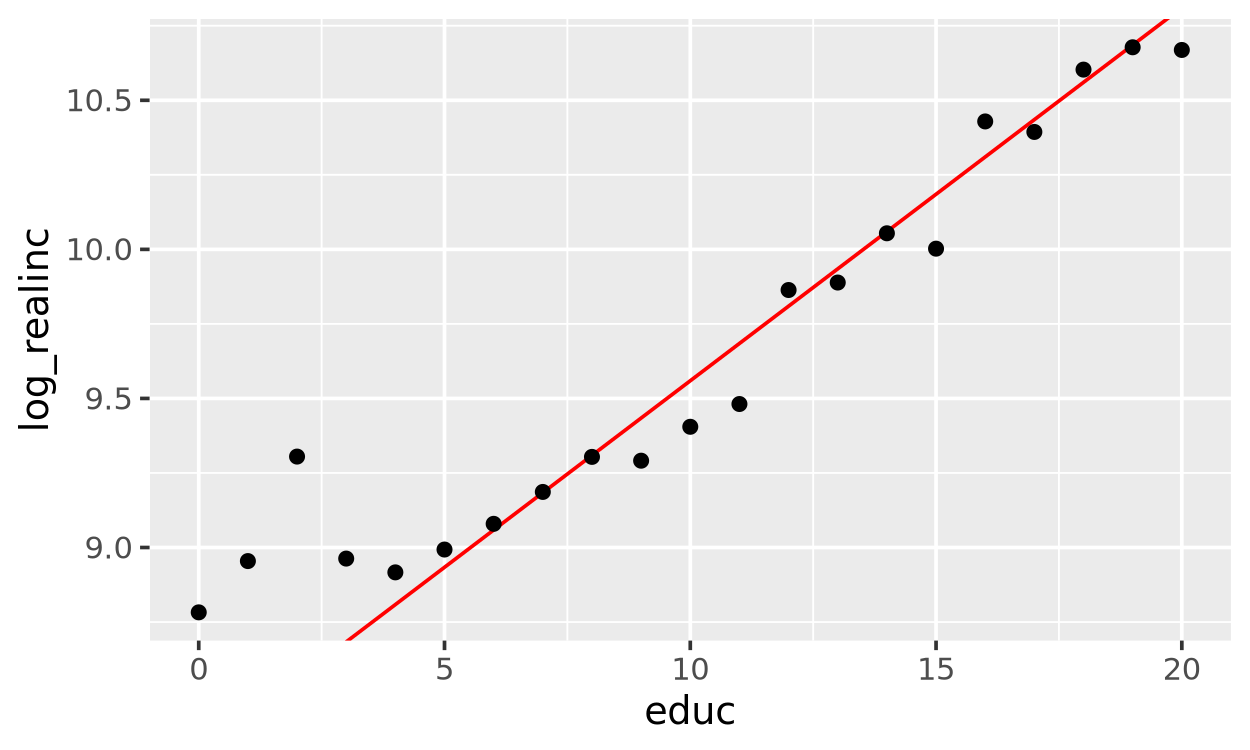

In [17]:
log_income_by_educ <- gss |>
    group_by(educ) |>
    summarize(log_realinc = mean(log(realinc)))

a_log <- tidy(fit_log)$estimate

ggplot(log_income_by_educ, aes(x = educ, y = log_realinc)) +
    geom_abline(intercept = a_log[1], slope = a_log[2], color = 'red') +
    geom_point()

From about 5 years up, the points fall close to the line. Below 5 years the line misses. Only about 1% of people are there, so they have little pull on the fit.

### How many dollars?

12.5% of what? That depends on how much you earn now.

Predict on a grid. `.pred` is on the log scale, so `exp()` takes it back to dollars.

In [18]:
grid_educ <- tibble(educ = c(12, 13, 19, 20))

fit_log |>
    predict(new_data = grid_educ) |>
    bind_cols(grid_educ) |>
    mutate(dollars = exp(.pred))

  .pred     educ dollars 
1  9.809543 12   18206.66
2  9.934661 13   20633.28
3 10.685368 19   43711.56
4 10.810486 20   49537.53

In [19]:
fit_log |>
    predict(new_data = grid_educ) |>
    bind_cols(grid_educ) |>
    mutate(dollars = exp(.pred), me = lead(dollars) - dollars)

  .pred     educ dollars  me       
1  9.809543 12   18206.66  2426.621
2  9.934661 13   20633.28 23078.281
3 10.685368 19   43711.56  5825.966
4 10.810486 20   49537.53        NA

(Again, ignore the row for 13 → 19.)

From 12 to 13 years, income goes up about $2,400. From 19 to 20, it goes up about $5,800. **One coefficient, different dollar effects.** The same 13% is a bigger number of dollars when you start from a higher income.

Look at the recipe we used for the line, the curve, and the log model. It was the same each time:

1. Make a grid of $x$ values.
2. `predict()` on the grid (on the dollar scale).
3. Take the difference with `lead(.pred) - .pred`.

The recipe does not care what the model looks like inside.

## The big idea

1. A **coefficient** is a parameter. It is one of the numbers the search picks.
2. A **marginal effect** is a prediction difference. It is what happens to the prediction when $x$ goes up by one.
3. They are the **same number** only for a straight line on the raw scale.

In the next exercise you will use the same recipe on a model where the outcome is a yes/no answer.